PLEASE REFER TO APPENDIX ON HOW TO RUN THE CODE, CHANGE THE FILE NAMES ACCORDINGLY IN ORDER FOR THE DATASETS TO BE IMPORTED ON YOUR SYSTEM. YOU CAN LOCATE THE WHEREABOUTS OF THE CSV'S BY CHECKING THE PATHWAY WHERE THE CODE IS TRYING TO IMPORT


USE localized_url function if there's an error with the imports

In [ ]:
import os
def localized_url(url):

    current_dir = os.getcwd().split("statistical-analysis-and-modeling-of-football-data")[0] + "statistical-analysis-and-modeling-of-football-data"
    branch = url.split("statistical-analysis-and-modeling-of-football-data")[1]
    return current_dir + branch

In [2]:
import requests
import json
import numpy as np
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
#ignore warnings
import warnings
warnings.filterwarnings("ignore")
import ScraperFC as sfc
import seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_absolute_percentage_error


In [4]:
indexes=pd.read_csv('understat_match_1524.csv')
epl_stats=pd.read_csv("understat_epl1524_processed.csv")


In [7]:
indexes.columns

Index(['id', 'fid', 'h', 'a', 'date', 'league_id', 'season', 'h_goals',
       'a_goals', 'team_h', 'team_a', 'h_xg', 'a_xg', 'h_w', 'h_d', 'h_l',
       'league', 'h_shot', 'a_shot', 'h_shotOnTarget', 'a_shotOnTarget',
       'h_deep', 'a_deep', 'a_ppda', 'h_ppda'],
      dtype='object')

In [9]:
indexes=indexes[['h_goals',
       'a_goals']]

In [10]:
#We have home_score and away_score, we need to create a new column for the outcome of the match depending on these scores
#If home_score > away_score, home team wins, if home_score < away_score, away team wins, if home_score == away_score, draw
indexes['outcome'] = np.where(indexes['h_goals'] > indexes['a_goals'], 'home',
                              np.where(indexes['h_goals'] < indexes['a_goals'], 'away', 'draw'))


In [13]:
indexes

,h_goals,a_goals,outcome
0,1,0,home
1,0,1,away
2,2,2,draw
3,4,2,home
4,1,3,away
...,...,...,...
3415,5,0,home
3416,2,0,home
3417,2,4,away
3418,3,1,home


In [12]:
indexes['outcome'].value_counts()

outcome
home    1536
away    1091
draw     793
Name: count, dtype: int64

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import LabelEncoder

def mlr(X, y):
    """
    Train and evaluate a multinomial logistic regression model.
    Also plots permutation feature importance.

    Parameters:
        X (DataFrame): Feature matrix
        y (Series): Target labels (e.g. 'home', 'away', 'draw')

    Returns:
        Trained sklearn pipeline
    """
    # Encode target if it's categorical
    le = LabelEncoder()
    y_encoded = le.fit_transform(y)

    # Split data
    X_train, X_test, y_train_encoded, y_test_encoded = train_test_split(
        X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
    )

    # Build pipeline
    scaler = StandardScaler()
    model = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=1000)
    pipeline = make_pipeline(scaler, model)

    # Fit model
    pipeline.fit(X_train, y_train_encoded)

    # Evaluate
    y_pred = pipeline.predict(X_test)
    print("Classification Report:\n", classification_report(y_test_encoded, y_pred, target_names=le.classes_))
    print("Confusion Matrix:\n", confusion_matrix(y_test_encoded, y_pred))

    # Get scaled X_test
    X_test_scaled = scaler.transform(X_test)

    # Permutation importance
    perm_imp = permutation_importance(
        model, X_test_scaled, y_test_encoded,
        scoring='accuracy', n_repeats=10, random_state=42
    )

    feature_importance = np.abs(perm_imp.importances_mean)
    feature_names = np.array(X.columns)
    sorted_idx = np.argsort(-feature_importance)

    # Plot
    plt.figure(figsize=(12, 5))
    plt.bar(range(len(sorted_idx)), feature_importance[sorted_idx], align="center")
    plt.xticks(range(len(sorted_idx)), feature_names[sorted_idx], rotation=90)
    plt.xlabel('Features')
    plt.ylabel('Permutation Importance')
    plt.title('Feature Importance for Logistic Regression')
    plt.tight_layout()
    plt.show()
    important_features_list = feature_names[sorted_idx]
    return pipeline, important_features_list


In [15]:
from sklearn.ensemble import RandomForestClassifier
def rf_classifier(X, y):
    """
    Train and evaluate a Random Forest classifier on match outcomes.

    Parameters:
        X (DataFrame): Feature matrix
        y (Series): Target labels ('home', 'away', 'draw')

    Returns:
        Trained pipeline model
    """
    # Split the data
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # Optional: standardize features (not strictly needed for tree-based models, but doesn't hurt)
    model = make_pipeline(
        StandardScaler(),
        RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
    )

    # Train the model
    model.fit(X_train, y_train)

    # Predict and evaluate
    y_pred = model.predict(X_test)
    print("Classification Report:\n", classification_report(y_test, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

    return model

In [16]:
indexes.columns

Index(['h_goals', 'a_goals', 'outcome'], dtype='object')

Classification Report:
               precision    recall  f1-score   support

        away       0.66      0.78      0.71       218
        draw       0.39      0.11      0.17       159
        home       0.68      0.84      0.75       307

    accuracy                           0.65       684
   macro avg       0.57      0.57      0.54       684
weighted avg       0.60      0.65      0.60       684

Confusion Matrix:
 [[169  17  32]
 [ 50  17  92]
 [ 39  10 258]]


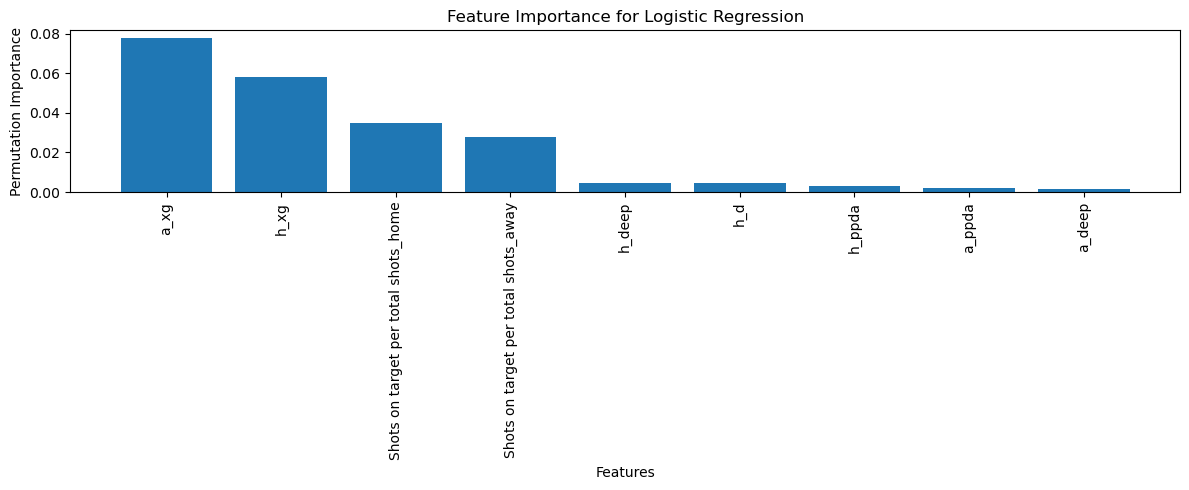

(Pipeline(steps=[('standardscaler', StandardScaler()),
                 ('logisticregression',
                  LogisticRegression(max_iter=1000, multi_class='multinomial'))]),
 array(['a_xg', 'h_xg', 'Shots on target per total shots_home',
        'Shots on target per total shots_away', 'h_deep', 'h_d', 'h_ppda',
        'a_ppda', 'a_deep'], dtype=object))

In [17]:
y=indexes['outcome']
X =epl_stats
mlr(X, y)

Classification Report:
               precision    recall  f1-score   support

        away       0.66      0.78      0.71       218
        draw       0.39      0.11      0.17       159
        home       0.68      0.84      0.75       307

    accuracy                           0.65       684
   macro avg       0.57      0.57      0.54       684
weighted avg       0.60      0.65      0.60       684

Confusion Matrix:
 [[169  17  32]
 [ 50  17  92]
 [ 39  10 258]]


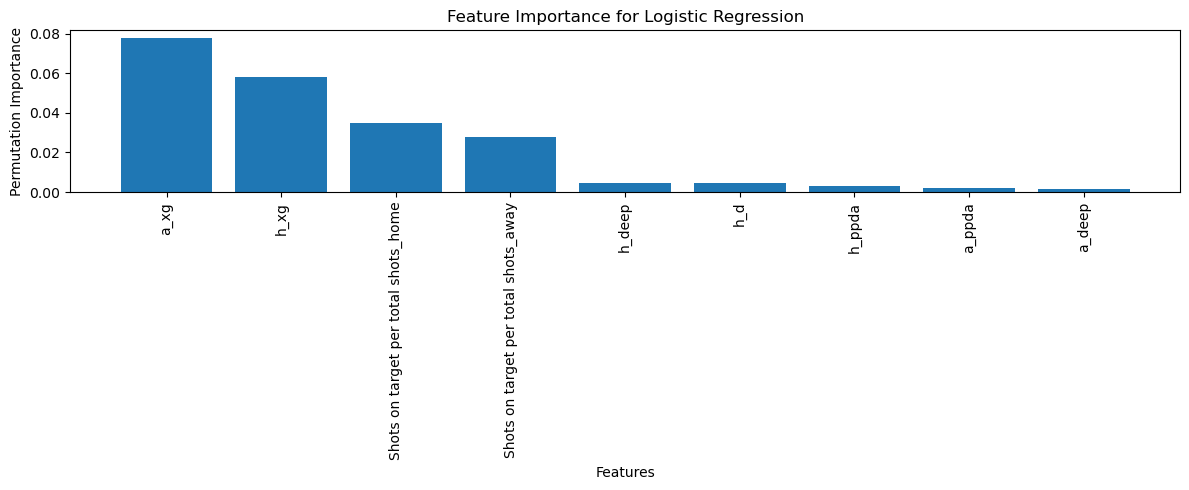

In [18]:
_,imp=mlr(X, y)

In [19]:
rf_classifier(X, y)

Classification Report:
               precision    recall  f1-score   support

        away       0.64      0.72      0.68       218
        draw       0.33      0.17      0.22       159
        home       0.68      0.79      0.73       307

    accuracy                           0.62       684
   macro avg       0.55      0.56      0.55       684
weighted avg       0.59      0.62      0.60       684

Confusion Matrix:
 [[158  31  29]
 [ 47  27  85]
 [ 41  24 242]]


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('randomforestclassifier',
                 RandomForestClassifier(class_weight='balanced',
                                        random_state=42))])

In [20]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Prepare data
X_np = X.values.astype('float32')
y_enc = LabelEncoder().fit_transform(y)
num_classes = len(set(y_enc))

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_np, y_enc, test_size=0.2, stratify=y_enc, random_state=42)

# Standardize
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert to tensors
X_train_tensor = torch.tensor(X_train)
y_train_tensor = torch.tensor(y_train)
X_test_tensor = torch.tensor(X_test)
y_test_tensor = torch.tensor(y_test)

# Wrap in DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)


In [21]:
class MatchOutcomeNN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(MatchOutcomeNN, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, x):
        return self.model(x)

In [22]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = MatchOutcomeNN(input_dim=X.shape[1], hidden_dim=64, output_dim=num_classes).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Training loop
for epoch in range(30):
    model.train()
    total_loss = 0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = loss_fn(outputs, y_batch)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss:.4f}")


Epoch 1, Loss: 74.9045
Epoch 2, Loss: 66.7953
Epoch 3, Loss: 65.9580
Epoch 4, Loss: 65.7375
Epoch 5, Loss: 65.1553
Epoch 6, Loss: 64.7861
Epoch 7, Loss: 64.3386
Epoch 8, Loss: 64.0654
Epoch 9, Loss: 63.9701
Epoch 10, Loss: 63.6657
Epoch 11, Loss: 63.4103
Epoch 12, Loss: 63.6166
Epoch 13, Loss: 63.2248
Epoch 14, Loss: 63.2857
Epoch 15, Loss: 62.4914
Epoch 16, Loss: 62.5171
Epoch 17, Loss: 62.5126
Epoch 18, Loss: 62.1088
Epoch 19, Loss: 62.0159
Epoch 20, Loss: 61.8104
Epoch 21, Loss: 61.4941
Epoch 22, Loss: 61.3715
Epoch 23, Loss: 61.3239
Epoch 24, Loss: 61.0754
Epoch 25, Loss: 60.7705
Epoch 26, Loss: 60.8323
Epoch 27, Loss: 60.5510
Epoch 28, Loss: 60.2279
Epoch 29, Loss: 59.6633
Epoch 30, Loss: 59.7777


In [23]:
from sklearn.metrics import classification_report

model.eval()
all_preds = []
all_true = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        outputs = model(X_batch)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_true.extend(y_batch.numpy())

print(classification_report(all_true, all_preds, target_names=LabelEncoder().fit(y).classes_))


              precision    recall  f1-score   support

        away       0.66      0.73      0.69       218
        draw       0.40      0.24      0.30       159
        home       0.70      0.79      0.75       307

    accuracy                           0.64       684
   macro avg       0.59      0.59      0.58       684
weighted avg       0.62      0.64      0.62       684

